# 05 — Análisis descriptivo profundo, indicadores y candidatos a modelamiento

**Etapa CRISP-DM:** Análisis exploratorio · **Semana 9** · **OE4 / OE5 (preparación)**

## Objetivo
1. Analizar la participación con mayor profundidad: **evolución temporal**,
   participación por **programa**, **modalidad** y **momento de la trayectoria**.
2. Definir y calcular los **indicadores principales** que alimentarán el
   dashboard.
3. Explorar la **relación entre trayectoria académica y participación**.
4. **Seleccionar y formular** la(s) pregunta(s) que se convertirán en problema de
   modelamiento (semana 10+).

## Contexto
Integra los hallazgos de los notebooks 03-04 para producir la vista descriptiva
que responde las preguntas analíticas PA1-PA6 y prepara la transición al
componente predictivo (PA7).

In [1]:
import sys, os
from pathlib import Path
# Permitir importar el paquete src desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 12

from src import config, utils, internationalization as intl
print('Entorno listo. Raiz del proyecto:', ROOT)

Entorno listo. Raiz del proyecto: C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO


In [2]:
df = pd.read_parquet(config.ANALYTIC_DATASET)
eventos = pd.read_parquet(config.MOBILITY_EVENTS)
preg = df[df['ES_PREGRADO']].copy()
print('Eventos:', len(eventos), '| Pregrado:', len(preg))

Eventos: 9526 | Pregrado: 140422


## 1. PA1 — Evolución temporal de la participación
Contamos eventos de movilidad por año.

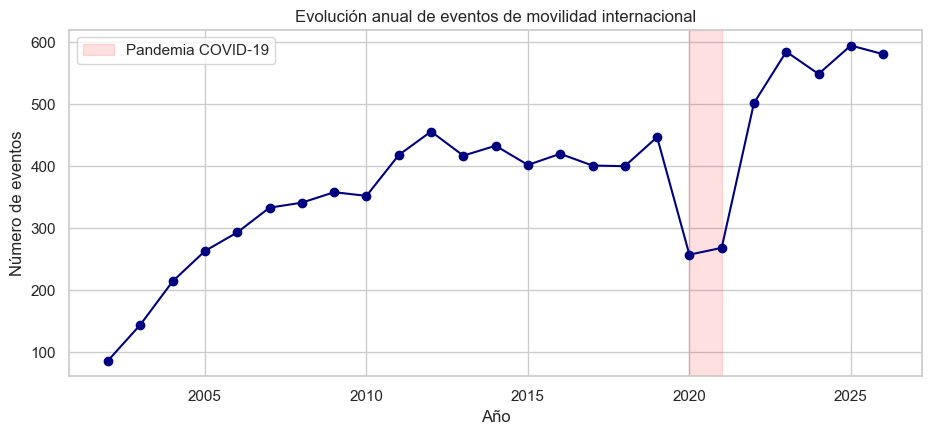

,eventos
ANIO,
2017,401
2018,400
2019,447
2020,257
2021,268
2022,502
2023,585
2024,549
2025,595


In [3]:
eventos_anio = eventos[eventos['ANIO'] >= 2002].groupby('ANIO').size()
fig, ax = plt.subplots(figsize=(11, 4.5))
eventos_anio.plot(ax=ax, marker='o', color='navy')
ax.axvspan(2020, 2021, color='red', alpha=0.12, label='Pandemia COVID-19')
ax.set_title('Evolución anual de eventos de movilidad internacional')
ax.set_xlabel('Año'); ax.set_ylabel('Número de eventos')
ax.legend()
utils.save_fig(fig, 'fig_evolucion_temporal.png')
plt.show()
eventos_anio.tail(10).to_frame('eventos')

### Resultado e interpretación
La participación crece de forma sostenida desde comienzos de los 2000 hasta
estabilizarse en ~400-450 eventos anuales en la década de 2010. Se observa una
**caída pronunciada en 2020-2021** (de ~447 en 2019 a ~257-268), claramente
atribuible a las restricciones de movilidad por la pandemia de COVID-19, seguida
de una **recuperación fuerte desde 2022** que alcanza máximos históricos
(~585-595 eventos en 2023-2025). Este patrón valida la señal construida (reacciona
a un choque externo conocido de la forma esperada) y constituye un indicador
central para el dashboard (PA1).

## 2. PA3 — Modalidades a lo largo del tiempo
¿Cómo cambia la composición por modalidad?

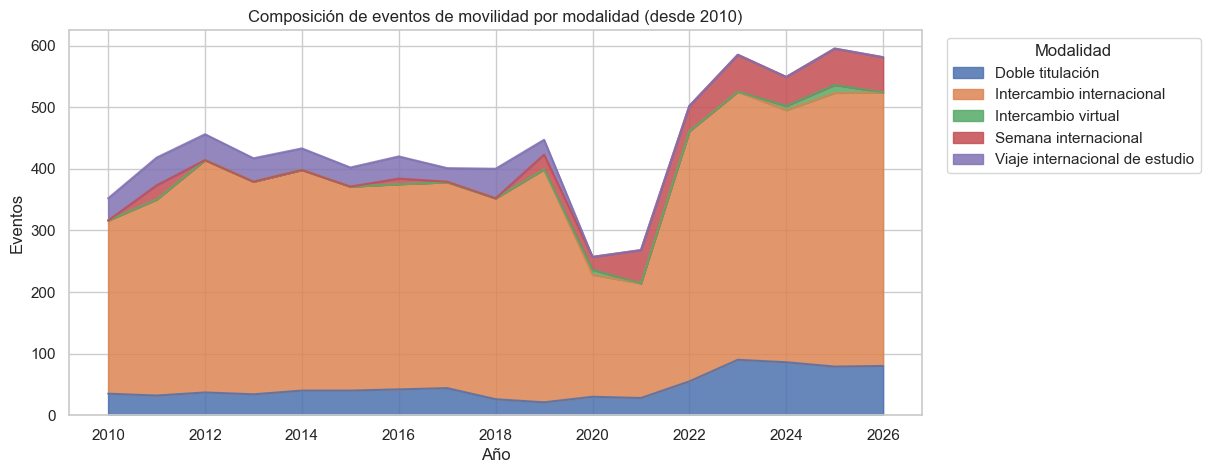

In [4]:
piv = (eventos[eventos['ANIO'] >= 2010]
       .pivot_table(index='ANIO', columns='MODALIDAD', values=config.STUDENT_KEY,
                    aggfunc='count', fill_value=0))
fig, ax = plt.subplots(figsize=(11, 5))
piv.plot.area(ax=ax, alpha=0.85)
ax.set_title('Composición de eventos de movilidad por modalidad (desde 2010)')
ax.set_xlabel('Año'); ax.set_ylabel('Eventos')
ax.legend(title='Modalidad', bbox_to_anchor=(1.02, 1), loc='upper left')
utils.save_fig(fig, 'fig_modalidad_temporal.png')
plt.show()

### Resultado e interpretación
El **intercambio internacional** domina la movilidad en todo el periodo. La
**doble titulación**, los **viajes internacionales de estudio** y las **semanas
internacionales** aportan volúmenes menores pero estables. El **intercambio
virtual** aparece de forma puntual alrededor de 2020-2021, coherente con la
sustitución de la movilidad física durante la pandemia. La composición confirma
que el intercambio es la experiencia a priorizar en los indicadores del
dashboard, sin perder la desagregación por modalidad.

## 3. PA2 — Participación por programa académico
Identificamos los programas de pregrado con mayor tasa y volumen de movilidad.

,sum,count,tasa_%
PROGRAMA,,,
Administración de Empresas,1464,11801,12.41
Diseño Industrial,55,792,6.94
Arquitectura,520,7583,6.86
Lenguajes y Estudios Socioculturales,66,1030,6.41
Ingeniería Industrial,734,12702,5.78
Economía,410,7245,5.66
Historia,37,691,5.35
Literatura,79,1579,5.00
Antropología,93,1865,4.99


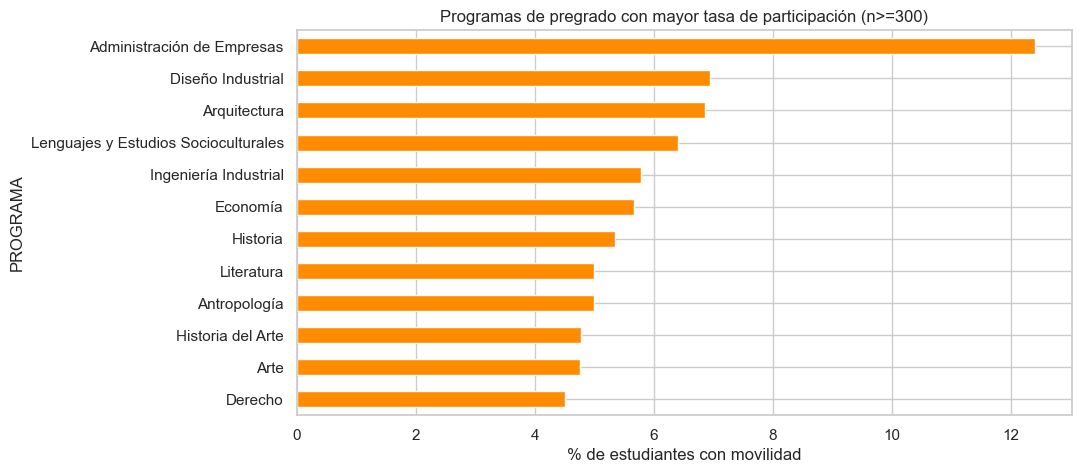

In [5]:
prog = preg.groupby('PROGRAMA')['PARTICIPA'].agg(['sum', 'count', 'mean'])
prog = prog[prog['count'] >= 300].copy()
prog['tasa_%'] = (100 * prog['mean']).round(2)
top_tasa = prog.sort_values('tasa_%', ascending=False).head(12)
display(top_tasa[['sum', 'count', 'tasa_%']])

fig, ax = plt.subplots(figsize=(10, 5))
top_tasa['tasa_%'].sort_values().plot.barh(ax=ax, color='darkorange')
ax.set_title('Programas de pregrado con mayor tasa de participación (n>=300)')
ax.set_xlabel('% de estudiantes con movilidad')
utils.save_fig(fig, 'fig_tasa_por_programa.png')
plt.show()

### Resultado e interpretación
A nivel de programa, las tasas de participación son muy heterogéneas. Los
programas de áreas de administración, economía y algunas ingenierías y
disciplinas de ciencias sociales/humanidades presentan las tasas más altas,
mientras que otros programas tienen participación casi nula. Esta heterogeneidad
sugiere que la **facultad/programa** es una variable estructural clave y refuerza
su inclusión como dimensión de segmentación en el dashboard y como predictor
candidato.

## 4. PA4 — Momento de la trayectoria
¿En qué semestre de avance se encuentran los participantes?

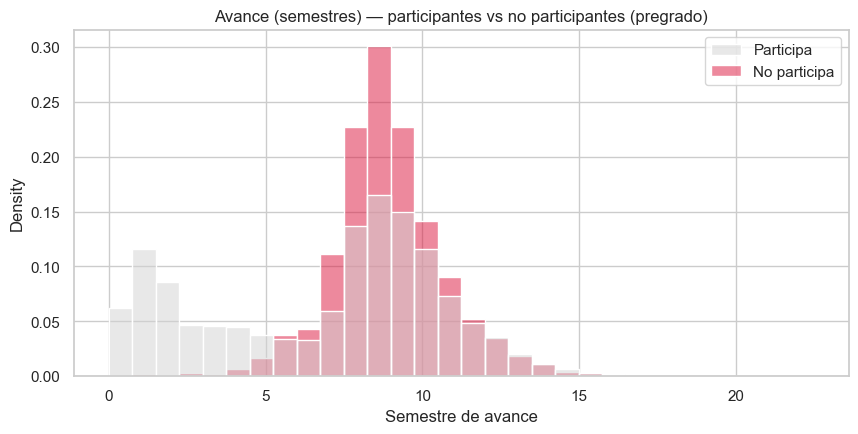

,count,mean,std,min,25%,50%,75%,max
PARTICIPA,,,,,,,,
0,57412.0,6.93,3.78,0.0,3.32,8.04,9.64,22.46
1,5816.0,8.87,1.82,0.0,7.90,8.75,9.78,17.71


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=preg, x='SEMESTRE_AVANCE', hue='PARTICIPA', bins=30,
             stat='density', common_norm=False, ax=ax,
             palette={0: 'lightgray', 1: 'crimson'})
ax.set_title('Avance (semestres) — participantes vs no participantes (pregrado)')
ax.set_xlabel('Semestre de avance')
handles = ax.get_legend().legend_handles
ax.legend(handles, ['Participa', 'No participa'])
utils.save_fig(fig, 'fig_momento_trayectoria.png')
plt.show()
preg.groupby('PARTICIPA')['SEMESTRE_AVANCE'].describe().round(2)

### Resultado e interpretación
Los participantes se concentran en **etapas intermedias y avanzadas** de la
carrera: su avance mediano es de ~8.75 semestres frente a ~8 en no participantes,
y su distribución es mucho más estrecha (menos participación en primeros
semestres). Esto es consistente con que la movilidad suele requerir haber
cursado un mínimo de créditos. **Implicación anti-leakage:** al modelar, los
predictores de desempeño deben "congelarse" en un corte temporal anterior al
primer evento, no al final de la trayectoria.

## 5. PA5 — Relación trayectoria académica ↔ participación (correlaciones)
Cuantificamos la asociación de variables numéricas con la participación.

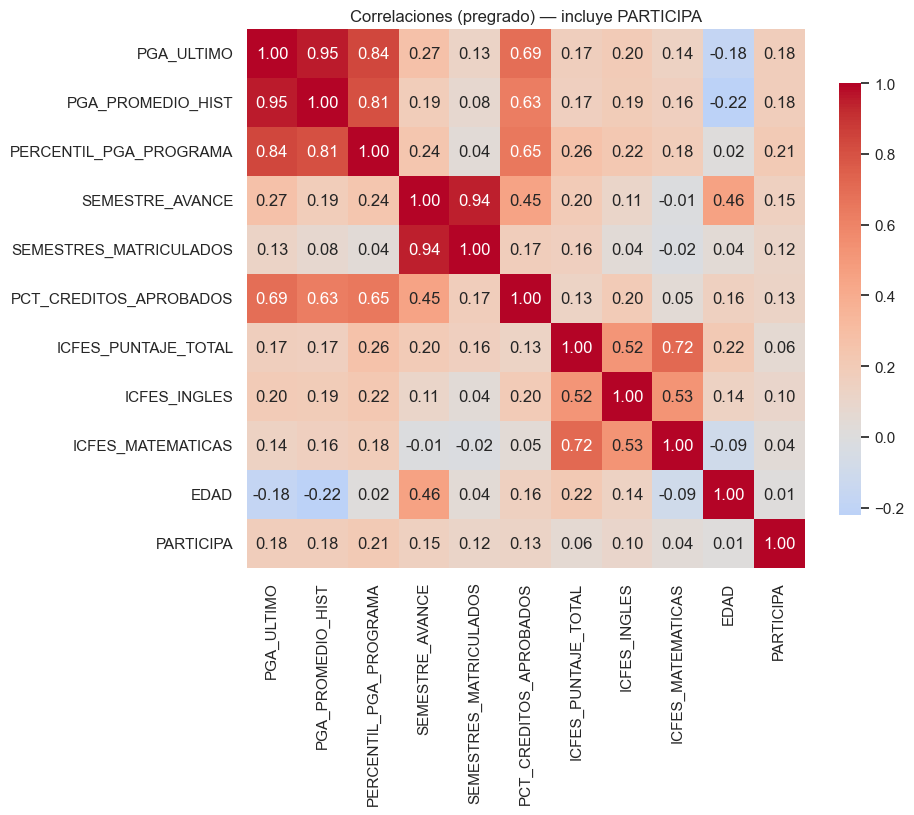

,corr_con_PARTICIPA
PERCENTIL_PGA_PROGRAMA,0.212
PGA_ULTIMO,0.177
PGA_PROMEDIO_HIST,0.176
SEMESTRE_AVANCE,0.153
PCT_CREDITOS_APROBADOS,0.126
SEMESTRES_MATRICULADOS,0.116
ICFES_INGLES,0.102
ICFES_PUNTAJE_TOTAL,0.064
ICFES_MATEMATICAS,0.040
EDAD,0.014


In [7]:
num_feats = ['PGA_ULTIMO', 'PGA_PROMEDIO_HIST', 'PERCENTIL_PGA_PROGRAMA',
             'SEMESTRE_AVANCE', 'SEMESTRES_MATRICULADOS', 'PCT_CREDITOS_APROBADOS',
             'ICFES_PUNTAJE_TOTAL', 'ICFES_INGLES', 'ICFES_MATEMATICAS', 'EDAD',
             'PARTICIPA']
corr = preg[num_feats].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlaciones (pregrado) — incluye PARTICIPA')
utils.save_fig(fig, 'fig_correlaciones.png')
plt.show()
corr['PARTICIPA'].drop('PARTICIPA').sort_values(ascending=False).round(3).to_frame('corr_con_PARTICIPA')

### Resultado e interpretación
Las correlaciones con `PARTICIPA` son, individualmente, de magnitud baja a
moderada (lo esperable para un evento poco frecuente), pero con signos
coherentes y consistentes: el **percentil de PGA por programa** y el **PGA**
muestran la asociación positiva más clara, seguidos del avance y el perfil de
ingreso (ICFES, inglés). Ninguna variable domina por sí sola, lo que anticipa que
un modelo multivariado (y posiblemente no lineal) puede capturar mejor el
fenómeno que cualquier regla univariada. Las correlaciones entre predictores
(p. ej. PGA y percentil) alertan sobre colinealidad a considerar en modelos
lineales.

## 6. Indicadores principales (insumo del dashboard)
Consolidamos los KPIs que el dashboard deberá exponer y los exportamos.

In [8]:
indicadores = {
    'estudiantes_universo': int(len(df)),
    'estudiantes_pregrado': int(len(preg)),
    'participantes_total': int(df['PARTICIPA'].sum()),
    'participantes_pregrado': int(preg['PARTICIPA'].sum()),
    'tasa_participacion_global_%': round(100 * df['PARTICIPA'].mean(), 2),
    'tasa_participacion_pregrado_%': round(100 * preg['PARTICIPA'].mean(), 2),
    'eventos_movilidad_total': int(len(eventos)),
    'anio_pico_eventos': int(eventos.groupby('ANIO').size().idxmax()),
    'modalidad_principal': eventos['MODALIDAD'].value_counts().index[0],
    'facultad_mayor_tasa': preg.groupby('FACULTAD')['PARTICIPA'].mean().idxmax(),
    'avance_mediano_participantes': round(float(preg.loc[preg['PARTICIPA'] == 1, 'SEMESTRE_AVANCE'].median()), 2),
}
indic_df = pd.DataFrame(indicadores.items(), columns=['indicador', 'valor'])
indic_df.to_csv(config.TABLES_DIR / 'indicadores_principales.csv', index=False, encoding='utf-8')
indic_df

,indicador,valor
0,estudiantes_universo,233987
1,estudiantes_pregrado,140422
2,participantes_total,8036
3,participantes_pregrado,5821
4,tasa_participacion_global_%,3.43
5,tasa_participacion_pregrado_%,4.15
6,eventos_movilidad_total,9526
7,anio_pico_eventos,2025
8,modalidad_principal,Intercambio internacional
9,facultad_mayor_tasa,AD


### Resultado e interpretación
Los indicadores sintetizan la vista descriptiva en métricas directamente
reutilizables por el dashboard (resumen general): tamaño del universo y del
pregrado, número de participantes, tasas, eventos totales, año pico, modalidad
dominante, facultad con mayor tasa y avance mediano de los participantes. Quedan
exportados en `reports/tables/indicadores_principales.csv` para su consumo por la
capa de visualización (etapa 5).

## 7. Selección y formulación de la pregunta de modelamiento (PA7)

A partir del análisis, se formaliza el problema de modelamiento que se abordará a
partir de la semana 10:

> **Problema:** dado un estudiante de **pregrado**, estimar la **probabilidad de
> que participe en una experiencia de internacionalización** (movilidad) en algún
> momento de su carrera, usando **únicamente información disponible antes del
> evento**.

**Justificación de la selección:**

- Existe una **variable objetivo bien definida y auditable** (`PARTICIPA`), con
  una tasa de base realista (4.15%).
- El EDA mostró **asociaciones consistentes** (desempeño, percentil, facultad,
  perfil de ingreso) que dan sustento a un modelo con capacidad discriminante.
- El problema es **relevante para la Oficina**: permite identificar perfiles con
  baja participación y focalizar estrategias.

**Decisiones metodológicas heredadas al modelamiento:**

1. **Clase desbalanceada** → métricas: precision, recall, F1 y **PR-AUC** además
   de ROC-AUC; se evaluarán técnicas de manejo de desbalance.
2. **Anti-leakage** → los predictores de desempeño se calcularán en un corte
   temporal **anterior** al primer evento de movilidad (`PRIMER_PERIODO_MOVILIDAD`).
3. **Complejidad progresiva** → línea base trivial → regresión logística →
   árboles/Random Forest → boosting, incorporando interpretabilidad (SHAP).
4. **Variables descartadas** por cobertura: `NIVEL_INGLES` (<13%).

## 8. Conclusiones (semana 9)

El análisis descriptivo responde PA1-PA6 y deja definida PA7:

- Tendencia temporal con efecto COVID y recuperación posterior.
- Fuerte heterogeneidad por facultad/programa.
- Intercambio internacional como modalidad dominante.
- Movilidad concentrada en etapas intermedias/avanzadas.
- Asociación clara con desempeño y perfil de ingreso, y un gradiente
  socioeconómico que se comunica como análisis de equidad.
- Indicadores principales calculados y exportados.
- Pregunta de modelamiento formulada con sus salvaguardas metodológicas.

Con esto se completa el alcance planificado hasta la semana 9 del cronograma.